### Check GPU colab

In [1]:
import torch
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

CUDA available: True
GPU: Tesla T4


### Load data

In [7]:
# download the zip datasets in content, then run this do unzip
!unzip -q /content/datasets.zip -d /content

In [8]:
import os
DATA_ROOT = '/content/datasets'
print(os.listdir(DATA_ROOT))
for split in ["train", "val"]:
    for c in ["cat", "dog"]:
        print(split, c, len(os.listdir(f"{DATA_ROOT}/{split}/{c}")))
print("test", len(os.listdir(f"{DATA_ROOT}/test")))

['val', '.DS_Store', 'test', 'train']
train cat 10000
train dog 10000
val cat 2500
val dog 2500
test 500


### Imports, config, seed

In [9]:
import os, random, time, copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset, Subset
from torchvision import datasets, transforms, models

SEED = 42
# folder that  contains train/, val/, test/
DATA_ROOT = '/content/datasets'
# local only, nothing saved in colab, download it before ending session
CKPT_DIR = '/content/checkpoints'
os.makedirs(CKPT_DIR, exist_ok=True)

IMG_SIZE = 224
BATCH_SIZE = 64
NUM_WORKERS = 2

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Fixed seed so every run gives same results (reproducibility, question b)
def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % 2**32
    np.random.seed(worker_seed)
    random.seed(worker_seed)

set_seed()
print("Device:", device)
# should show train, val, test
print("Dataset folders:", os.listdir(DATA_ROOT))

Device: cuda
Dataset folders: ['val', '.DS_Store', 'test', 'train']


### transforms

In [10]:
# Standard values for resnet18 normalization
MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]

# Augmentation (crop, flip, rotation, colour jitter) is applied to TRAIN only
# Val/test only get resize + normalize, so evaluation stays deterministic
def get_transforms(img_size=IMG_SIZE, augment=True):
    if augment:
        train_tf = transforms.Compose([
            transforms.RandomResizedCrop(img_size, scale=(0.7, 1.0)),
            transforms.RandomHorizontalFlip(p=0.5),
            transforms.RandomRotation(15),
            transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
            transforms.ToTensor(),
            transforms.Normalize(MEAN, STD),
        ])
    else:
        train_tf = transforms.Compose([
            transforms.Resize((img_size, img_size)),
            transforms.ToTensor(),
            transforms.Normalize(MEAN, STD),
        ])
    eval_tf = transforms.Compose([
        transforms.Resize((img_size, img_size)),
        transforms.ToTensor(),
        transforms.Normalize(MEAN, STD),
    ])
    return train_tf, eval_tf

### data loaders

In [16]:
# n_per_class to train on small balanced subsets for fast experiments
def balanced_subset(dataset, n_per_class, seed=SEED):
    if n_per_class is None:
        return dataset
    rng = np.random.RandomState(seed)
    targets = np.array(dataset.targets)
    indices = []
    for c in np.unique(targets):
        idx = np.where(targets == c)[0]
        indices.extend(rng.choice(idx, size=min(n_per_class, len(idx)), replace=False).tolist())
    rng.shuffle(indices)
    return Subset(dataset, [int(i) for i in indices])


def make_loaders(n_train_per_class=None, n_val_per_class=None, batch_size=BATCH_SIZE,
                 img_size=IMG_SIZE, augment=True, seed=SEED):
    train_tf, eval_tf = get_transforms(img_size, augment)
    # ImageFolder gives labels from folder names (alphabetical): cat=0, dog=1
    train_full = datasets.ImageFolder(f"{DATA_ROOT}/train", transform=train_tf)
    val_full = datasets.ImageFolder(f"{DATA_ROOT}/val", transform=eval_tf)
    assert train_full.class_to_idx == {"cat": 0, "dog": 1}, train_full.class_to_idx

    train_ds = balanced_subset(train_full, n_train_per_class, seed)
    val_ds = balanced_subset(val_full, n_val_per_class, seed)

    g = torch.Generator()
    g.manual_seed(seed)
    # shuffle=True for train only; the val loader keeps its order
    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True,
                              num_workers=NUM_WORKERS, pin_memory=True,
                              worker_init_fn=seed_worker, generator=g)
    val_loader = DataLoader(val_ds, batch_size=batch_size, shuffle=False,
                            num_workers=NUM_WORKERS, pin_memory=True)
    return train_loader, val_loader


train_loader, val_loader = make_loaders()
print(f"Train: {len(train_loader.dataset)} | Val: {len(val_loader.dataset)}")

x, y = next(iter(train_loader))
print("Batch:", x.shape, y.shape)

Train: 20000 | Val: 5000
Batch: torch.Size([64, 3, 224, 224]) torch.Size([64])


### plot of some of the augmented images

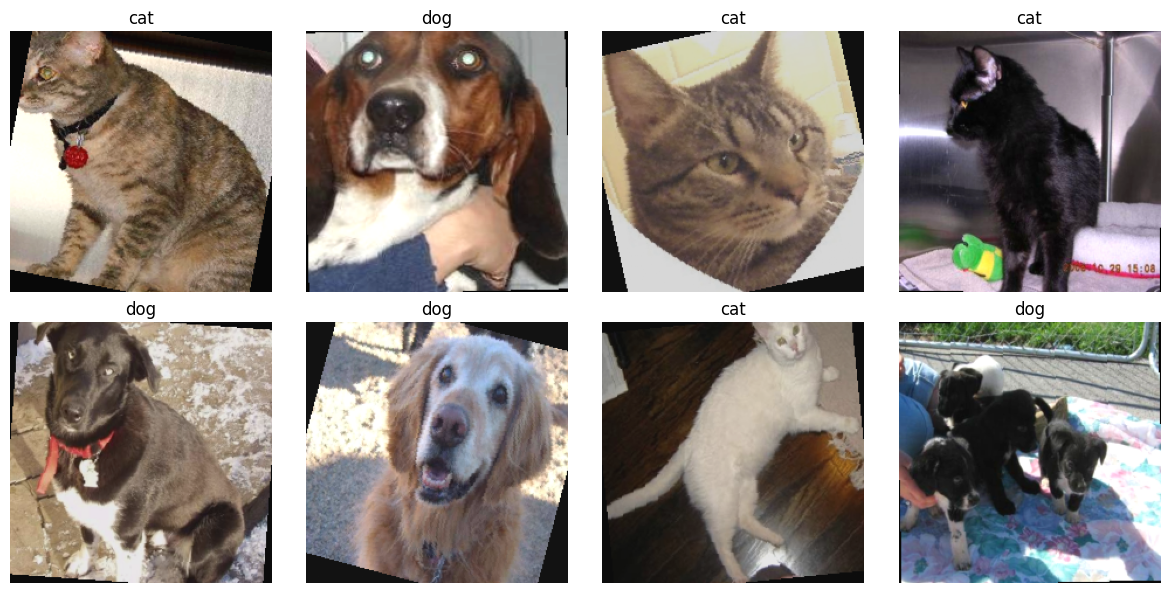

In [17]:
def show_batch(loader, n=8):
    imgs, labels = next(iter(loader))
    mean = torch.tensor(MEAN).view(3, 1, 1)
    std = torch.tensor(STD).view(3, 1, 1)
    fig, axes = plt.subplots(2, n // 2, figsize=(12, 6))
    for ax, img, lab in zip(axes.flat, imgs[:n], labels[:n]):
        ax.imshow((img * std + mean).clamp(0, 1).permute(1, 2, 0))
        ax.set_title("dog" if lab == 1 else "cat")
        ax.axis("off")
    plt.tight_layout()
    # remove comment underneath if we want to save it (maybe for report?)
    #plt.savefig("augmented_samples.png", dpi=150)
    plt.show()

show_batch(train_loader)

### model, loss, optimizer

In [18]:
def build_model(freeze_backbone=False):
    model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
    # freeze_backbone=True trains only the new head (fast); False fine-tunes the whole network
    if freeze_backbone:
        for p in model.parameters():
            p.requires_grad = False
    # Transfer learning: ResNet-18 pretrained on ImageNet, we only replace the final layer (512 -> 2 classes)
    model.fc = nn.Linear(model.fc.in_features, 2)   # 512 to 2 classes
    return model.to(device)

# Backbone gets a 10x smaller learning rate than the head so we don't destroy the pretrained features
def make_optimizer(model, lr=1e-3, weight_decay=1e-4, backbone_lr_mult=0.1):
    head_params = list(model.fc.parameters())
    head_ids = {id(p) for p in head_params}
    backbone_params = [p for p in model.parameters()
                       if id(p) not in head_ids and p.requires_grad]
    groups = [{"params": head_params, "lr": lr}]
    if backbone_params:
        groups.append({"params": backbone_params, "lr": lr * backbone_lr_mult})
    return torch.optim.AdamW(groups, weight_decay=weight_decay)


criterion = nn.CrossEntropyLoss()

model = build_model()
print(model.fc)
print("Trainable params:", sum(p.numel() for p in model.parameters() if p.requires_grad))

Linear(in_features=512, out_features=2, bias=True)
Trainable params: 11177538


### training functions

In [19]:
def run_epoch(model, loader, criterion, optimizer=None, scaler=None):
    training = optimizer is not None
    model.train(training)
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for x, y in loader:
            x = x.to(device, non_blocking=True)
            y = y.to(device, non_blocking=True)
            with torch.autocast(device_type=device.type, enabled=(device.type == "cuda")):
                out = model(x)
                loss = criterion(out, y)
            if training:
                optimizer.zero_grad(set_to_none=True)
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
            total_loss += loss.item() * x.size(0)
            correct += (out.argmax(1) == y).sum().item()
            n += x.size(0)
    return total_loss / n, correct / n


def fit(model, train_loader, val_loader, lr=1e-3, weight_decay=1e-4, epochs=5,
        patience=3, ckpt_path=None, verbose=True):
    optimizer = make_optimizer(model, lr, weight_decay)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
    scaler = torch.amp.GradScaler(enabled=(device.type == "cuda"))

    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    best_acc, best_state, bad_epochs = 0.0, None, 0

    for epoch in range(epochs):
        t0 = time.time()
        tr_loss, tr_acc = run_epoch(model, train_loader, criterion, optimizer, scaler)
        va_loss, va_acc = run_epoch(model, val_loader, criterion)
        scheduler.step()

        for k, v in zip(history, [tr_loss, tr_acc, va_loss, va_acc]):
            history[k].append(v)
        if verbose:
            print(f"Epoch {epoch+1}/{epochs} | train loss {tr_loss:.4f} acc {tr_acc:.4f} | "
                  f"val loss {va_loss:.4f} acc {va_acc:.4f} | {time.time()-t0:.0f}s")

        if va_acc > best_acc:
            best_acc, bad_epochs = va_acc, 0
            best_state = copy.deepcopy(model.state_dict())
            if ckpt_path:
                torch.save(best_state, ckpt_path)
        else:
            bad_epochs += 1
            if bad_epochs >= patience:
                print("Early stopping")
                break

    model.load_state_dict(best_state)
    return history, best_acc

### quick baseline with "basic" parameters (less than 2mn train)

In [20]:
set_seed()
small_train, small_val = make_loaders(n_train_per_class=1000, n_val_per_class=250)
model = build_model()
hist, best = fit(model, small_train, small_val, lr=1e-3, epochs=3)
print("Best val acc (subset baseline):", best)

Epoch 1/3 | train loss 0.1611 acc 0.9230 | val loss 0.0531 acc 0.9780 | 15s
Epoch 2/3 | train loss 0.0612 acc 0.9765 | val loss 0.0597 acc 0.9820 | 13s
Epoch 3/3 | train loss 0.0224 acc 0.9940 | val loss 0.0535 acc 0.9800 | 13s
Best val acc (subset baseline): 0.982


### tuning with random search (may take around 5min)

In [22]:
# Random search on a small subset with few epochs: cheap way to compare configs
# lr and weight decay are sampled on a LOG scale because they matter by orders of magnitude
# param selection uses ONLY VAL set, never test set

def run_experiment(lr, weight_decay, freeze_backbone, epochs=3):
    set_seed()
    model = build_model(freeze_backbone=freeze_backbone)
    _, best = fit(model, small_train, small_val, lr=lr, weight_decay=weight_decay,
                  epochs=epochs, patience=epochs, verbose=False)
    return best

rng = np.random.RandomState(0)
results = []
N_TRIALS = 8
for t in range(N_TRIALS):
    lr = 10 ** rng.uniform(-4, -2)
    wd = 10 ** rng.uniform(-6, -3)
    freeze = bool(rng.rand() < 0.3)
    acc = run_experiment(lr, wd, freeze)
    results.append({"lr": lr, "weight_decay": wd, "freeze_backbone": freeze, "val_acc": acc})
    print(f"Trial {t+1}/{N_TRIALS}: lr={lr:.2e} wd={wd:.2e} freeze={freeze} -> {acc:.4f}")

results_df = pd.DataFrame(results).sort_values("val_acc", ascending=False).reset_index(drop=True)
#results_df.to_csv("tuning_results.csv", index=False)
results_df

Trial 1/8: lr=1.25e-03 wd=1.40e-04 freeze=False -> 0.9820
Trial 2/8: lr=1.23e-03 wd=1.87e-05 freeze=False -> 0.9800
Trial 3/8: lr=7.50e-04 wd=4.73e-04 freeze=False -> 0.9880
Trial 4/8: lr=5.85e-04 wd=2.37e-04 freeze=False -> 0.9860
Trial 5/8: lr=1.37e-03 wd=5.98e-04 freeze=True -> 0.9640
Trial 6/8: lr=1.49e-04 wd=1.15e-06 freeze=False -> 0.9700
Trial 7/8: lr=3.60e-03 wd=4.07e-04 freeze=False -> 0.9760
Trial 8/8: lr=3.97e-03 wd=2.42e-05 freeze=False -> 0.9740


,lr,weight_decay,freeze_backbone,val_acc
0,0.000750,0.000473,False,0.988
1,0.000585,0.000237,False,0.986
2,0.001252,0.000140,False,0.982
3,0.001230,0.000019,False,0.980
4,0.003600,0.000407,False,0.976
5,0.003966,0.000024,False,0.974
6,0.000149,0.000001,False,0.970
7,0.001368,0.000598,True,0.964


### train on full data (10 to 15min)

In [23]:
# Retrain with the best config on the full training data (20,000 images) and save the best checkpoint
best_cfg = results_df.iloc[0]
print(best_cfg)

set_seed()
train_loader, val_loader = make_loaders()
model = build_model(freeze_backbone=bool(best_cfg["freeze_backbone"]))
CKPT_PATH = f"{CKPT_DIR}/resnet18_best.pt"

history, best_val_acc = fit(model, train_loader, val_loader,
                            lr=float(best_cfg["lr"]),
                            weight_decay=float(best_cfg["weight_decay"]),
                            epochs=6, patience=3, ckpt_path=CKPT_PATH)
print("Best validation accuracy:", best_val_acc)

lr                  0.00075
weight_decay       0.000473
freeze_backbone       False
val_acc               0.988
Name: 0, dtype: object
Epoch 1/6 | train loss 0.0714 acc 0.9715 | val loss 0.0334 acc 0.9868 | 147s
Epoch 2/6 | train loss 0.0369 acc 0.9859 | val loss 0.0418 acc 0.9864 | 130s
Epoch 3/6 | train loss 0.0230 acc 0.9918 | val loss 0.0331 acc 0.9884 | 127s
Epoch 4/6 | train loss 0.0176 acc 0.9940 | val loss 0.0302 acc 0.9894 | 128s
Epoch 5/6 | train loss 0.0103 acc 0.9969 | val loss 0.0292 acc 0.9914 | 134s
Epoch 6/6 | train loss 0.0088 acc 0.9971 | val loss 0.0316 acc 0.9902 | 130s
Best validation accuracy: 0.9914


### training curves (for report ?)

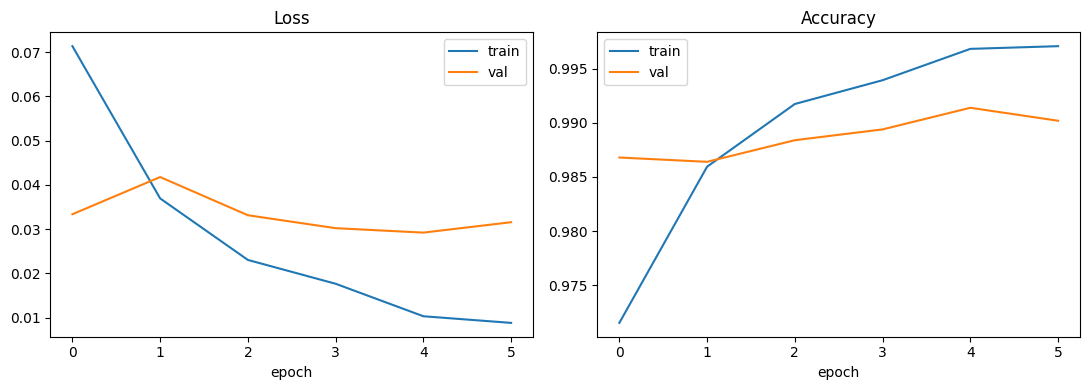

In [24]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(history["train_loss"], label="train")
ax[0].plot(history["val_loss"], label="val")
ax[0].set_title("Loss"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].plot(history["train_acc"], label="train")
ax[1].plot(history["val_acc"], label="val")
ax[1].set_title("Accuracy"); ax[1].set_xlabel("epoch"); ax[1].legend()
plt.tight_layout()
# remove comment underneath to save
#plt.savefig("training_curves.png", dpi=150)
plt.show()

### validation metrics

In [25]:
from sklearn.metrics import confusion_matrix, classification_report

_, eval_tf = get_transforms()
val_full = datasets.ImageFolder(f"{DATA_ROOT}/val", transform=eval_tf)
val_eval_loader = DataLoader(val_full, batch_size=BATCH_SIZE, shuffle=False,
                             num_workers=NUM_WORKERS)

model.eval()
all_preds, all_labels, all_conf = [], [], []
with torch.no_grad():
    for x, y in val_eval_loader:
        out = model(x.to(device))
        prob = torch.softmax(out, dim=1)
        all_preds.extend(prob.argmax(1).cpu().tolist())
        all_conf.extend(prob.max(1).values.cpu().tolist())
        all_labels.extend(y.tolist())

all_preds, all_labels, all_conf = np.array(all_preds), np.array(all_labels), np.array(all_conf)
print("Validation accuracy:", (all_preds == all_labels).mean())
print(confusion_matrix(all_labels, all_preds))
print(classification_report(all_labels, all_preds, target_names=["cat", "dog"], digits=4))

Validation accuracy: 0.9914
[[2477   23]
 [  20 2480]]
              precision    recall  f1-score   support

         cat     0.9920    0.9908    0.9914      2500
         dog     0.9908    0.9920    0.9914      2500

    accuracy                         0.9914      5000
   macro avg     0.9914    0.9914    0.9914      5000
weighted avg     0.9914    0.9914    0.9914      5000

